# Model V3 (Updated): Risk-Adjusted Satisfaction Prediction

### Methodology Update:
- **Class 1 (Risk):** Dissatisfied customers (Review Score 1, 2, 3). This represents our "Red Flags."
- **Class 0 (Safe):** Satisfied customers (Review Score 4, 5).
- **Optimization:** We are moving away from the default 0.5 threshold. For Olist, it is better to flag a potentially unhappy customer (False Positive) than to miss one who is about to leave a 1-star review (False Negative).

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load and Define Labels
df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')
df['is_dissatisfied'] = (df['review_score'] < 4).astype(int)

# 2. Advanced Feature Engineering
df['log_price'] = np.log1p(df['price'])
df['log_distance'] = np.log1p(df['distance_km'])
df['delivery_delta'] = df['actual_delivery_days'] - df['estimated_delivery_days']
df['prep_to_delivery_ratio'] = df['preparation_days'] / (df['actual_delivery_days'] + 1)

features = [
    'actual_delivery_days', 'delivery_delta', 'preparation_days', 
    'log_distance', 'log_price', 'product_photos_qty', 
    'product_description_lenght', 'is_late', 'prep_to_delivery_ratio', 
    'seller_id', 'product_category_name'
]

X = df[features].copy()
y = df['is_dissatisfied']

# 3. Target Encoding (Smoothing to avoid leakage)
global_mean = y.mean()
for col in ['seller_id', 'product_category_name']:
    mapping = y.groupby(df[col]).mean()
    X[col] = df[col].map(mapping).fillna(global_mean)

X = X.fillna(X.median())

# 4. Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Target distribution: {y.value_counts(normalize=True).to_dict()}")

Target distribution: {0: 0.7890889641647353, 1: 0.21091103583526474}


## 1. Train and Tune Threshold

We train the model and then analyze the probabilities to find the threshold that catches the most 'Red Flags'.

In [2]:
ratio = float(y_train.value_counts()[0]) / y_train.value_counts()[1]

xgb_final = XGBClassifier(
    n_estimators=1000, learning_rate=0.03, max_depth=8, 
    scale_pos_weight=ratio, random_state=42, eval_metric='auc', 
    early_stopping_rounds=50
)

xgb_final.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

y_prob = xgb_final.predict_proba(X_test)[:, 1]

# FIND OPTIMAL THRESHOLD (Maximizing F1 or Recall)
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
opt_threshold = thresholds[np.argmax(f1_scores)]

print(f"Optimal Threshold for balance: {opt_threshold:.4f}")

# Apply optimal threshold
y_pred_tuned = (y_prob >= opt_threshold).astype(int)

print("\nClassification Report (Tuned Threshold):")
print(classification_report(y_test, y_pred_tuned))

Optimal Threshold for balance: 0.5185

Classification Report (Tuned Threshold):
              precision    recall  f1-score   support

           0       0.86      0.81      0.83     15049
           1       0.42      0.51      0.46      4022

    accuracy                           0.75     19071
   macro avg       0.64      0.66      0.65     19071
weighted avg       0.77      0.75      0.76     19071



## 2. Risk Factor Insights

Which variables are the most reliable 'Red Flags'?

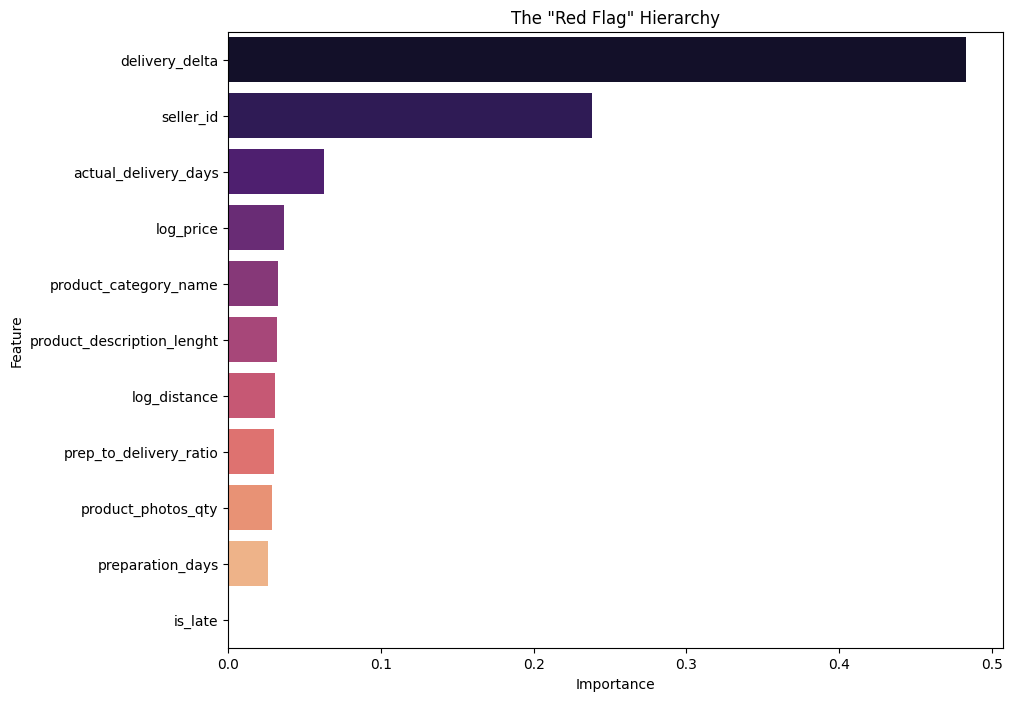

In [3]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_final.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, hue='Feature', palette='magma', legend=False)
plt.title('The "Red Flag" Hierarchy')
plt.show()

## 3. Confusion Matrix (Tuned Detector)

This matrix shows how many dissatisfied customers we caught using the tuned threshold.

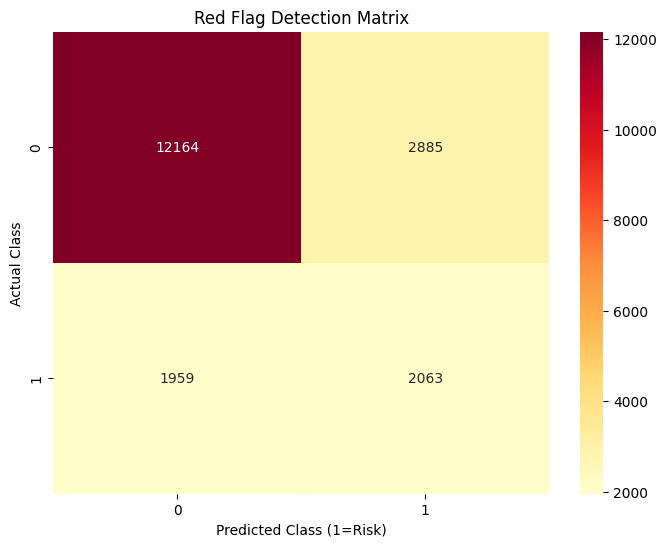

In [4]:
cm = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Red Flag Detection Matrix')
plt.xlabel('Predicted Class (1=Risk)')
plt.ylabel('Actual Class')
plt.show()

In [1]:
import pandas as pd

In [4]:
df = pd.read_csv(r'C:\Users\Admin\OneDrive\Desktop\Coursework\semester 6\AML Business\Project\AMLB\brazil_ecommerce\datasets\processed\olist_merged_clean.csv')
df.shape

(96189, 34)